# [IAPR][iapr]: Final project - Chocolate Recognition


**Moodle group ID:** *xx*  
**Kaggle challenge:** *xx* (either `Classic` or `Deep learning`)  
**Kaggle team name (exact):** "*xx*"  

**Author 1 (SCIPER):** *Student Name 1 (xxxxx)*  
**Author 2 (SCIPER):** *Student Name 2 (xxxxx)*  
**Author 3 (SCIPER):** *Student Name 3 (xxxxx)*  

**Due date:** 21.05.2025 (11:59 pm)


## Key Submission Guidelines:
- **Before submitting your notebook, <span style="color:red;">rerun</span> it from scratch!** Go to: `Kernel` > `Restart & Run All`
- **Only groups of three will be accepted**, except in exceptional circumstances.


[iapr]: https://github.com/LTS5/iapr2025

---

> Your comments  
> ...

### Imports :

In [1]:
import os
import sys 
assert (sys.version_info.major == 3) and (sys.version_info.minor == 9)

In [2]:
# if not done yet, install the required packages :
#!pip install -r requirements.txt

In [3]:
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from sklearn.metrics import mean_absolute_error, r2_score
from tqdm import tqdm
import matplotlib.pyplot as plt
from IPython.display import clear_output
import torch.nn as nn
import torch.nn.functional as F
import torch.nn.init as init

import cv2 as cv
import numpy as np
import math
from pathlib import Path


import glob
import re

In [4]:
# I HOPE WE ARE ALLOWED TO USE THIS PACKAGE !!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
#!pip install torchsummary
from torchsummary import summary

### Pre-processing par seuil bof: For HSV, hue range is [0,179], saturation range is [0,255], and value range is [0,255]

Traitement de : L1000756.JPG


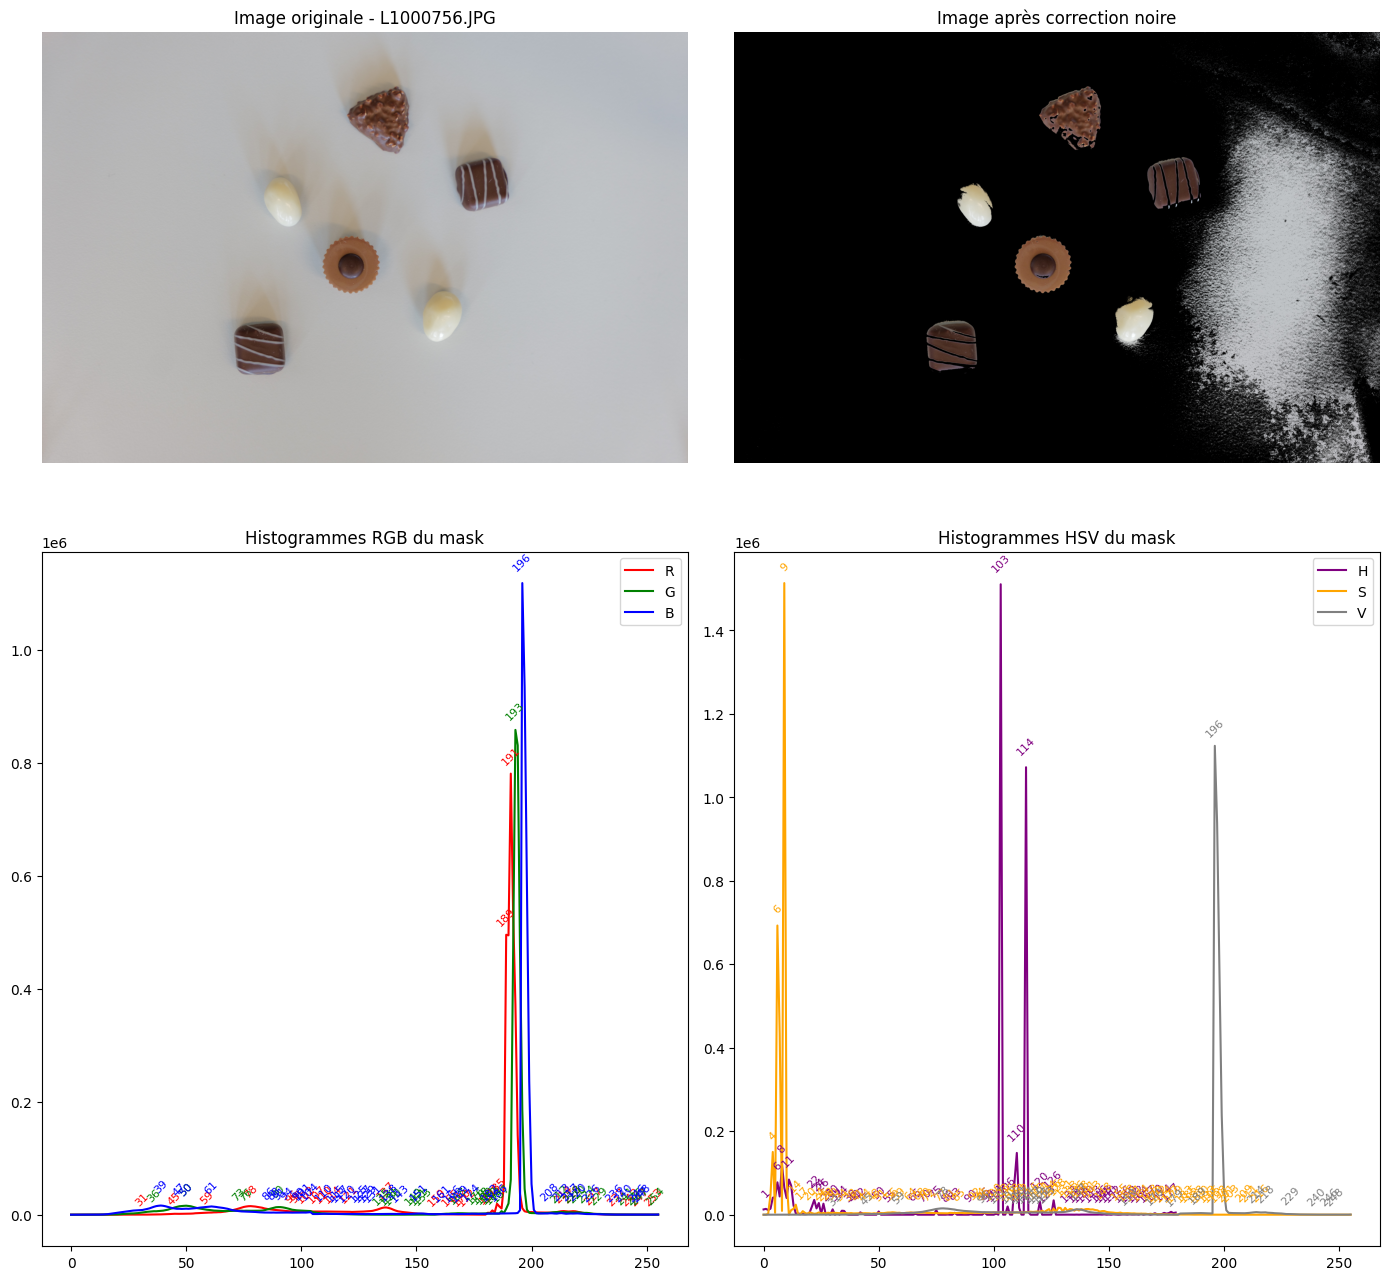

Traitement de : L1000763.JPG


In [ ]:
from scipy.signal import find_peaks

def annotate_peaks(ax, hist, color, height=0.01):
    peaks, _ = find_peaks(hist, height=height)
    for p in peaks:
        ax.annotate(f"{int(p)}", xy=(p, hist[p]), xytext=(p, hist[p] + max(hist)*0.02),
                    textcoords='data', ha='center', fontsize=8, color=color, rotation=45)

# Dossier des images
img_dir = "dataset_project_iapr2025/train/"
img_files = sorted([f for f in os.listdir(img_dir) if f.lower().endswith(".jpg")])

# Itérer sur toutes les images
for filename in img_files:
    print(f"Traitement de : {filename}")
    path = os.path.join(img_dir, filename)

    # === Ton pipeline (inchangé) ===
    img = cv.imread(path)
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Masquage noir
    img_noir = img.copy()
    img_noir_rgb = cv.cvtColor(img_noir, cv.COLOR_BGR2RGB)

    # mask BACKGROUND
    mask_rgb = (
        (img_noir_rgb[:, :, 0] >= 105) & (img_noir_rgb[:, :, 0] <= 195) &
        (img_noir_rgb[:, :, 1] >= 105) & (img_noir_rgb[:, :, 1] <= 195) &
        (img_noir_rgb[:, :, 2] >= 105) & (img_noir_rgb[:, :, 2] <= 195)
    )

    img_noir_hsv = cv.cvtColor(img_noir_rgb, cv.COLOR_RGB2HSV)

    mask_hsv = (
        (((img_noir_hsv[:, :, 0] >= 110) & (img_noir_hsv[:, :, 0] <= 120)) |
        ((img_noir_hsv[:, :, 1] >= 0) & (img_noir_hsv[:, :, 1] <= 50))) |
        ((img_noir_hsv[:, :, 2] >= 120) & (img_noir_hsv[:, :, 2] <= 180))
    )

    mask_total = mask_rgb & mask_hsv
    img_noir_rgb[mask_total] = [0, 0, 0]
    mask_choco = np.where(mask_total, 0, 255).astype(np.uint8)

    # Histogrammes
    img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)
    r_hist = cv.calcHist([img_rgb], [0], mask_choco, [256], [0, 256]).flatten()
    g_hist = cv.calcHist([img_rgb], [1], mask_choco, [256], [0, 256]).flatten()
    b_hist = cv.calcHist([img_rgb], [2], mask_choco, [256], [0, 256]).flatten()
    h_hist = cv.calcHist([img_hsv], [0], mask_choco, [180], [0, 180]).flatten()
    s_hist = cv.calcHist([img_hsv], [1], mask_choco, [256], [0, 256]).flatten()
    v_hist = cv.calcHist([img_hsv], [2], mask_choco, [256], [0, 256]).flatten()

    # Figure 1
    fig, axs = plt.subplots(2, 2, figsize=(14, 14))
    axs[0, 0].imshow(img_rgb)
    axs[0, 0].set_title(f"Image originale - {filename}")
    axs[0, 0].axis("off")

    axs[0, 1].imshow(img_noir_rgb)
    axs[0, 1].set_title("Image après correction noire")
    axs[0, 1].axis("off")

    axs[1, 0].plot(r_hist, color='r', label='R')
    axs[1, 0].plot(g_hist, color='g', label='G')
    axs[1, 0].plot(b_hist, color='b', label='B')
    axs[1, 0].set_title("Histogrammes RGB du mask")
    axs[1, 0].legend()
    annotate_peaks(axs[1, 0], r_hist, color='r')
    annotate_peaks(axs[1, 0], g_hist, color='g')
    annotate_peaks(axs[1, 0], b_hist, color='b')

    axs[1, 1].plot(h_hist, color='purple', label='H')
    axs[1, 1].plot(s_hist, color='orange', label='S')
    axs[1, 1].plot(v_hist, color='gray', label='V')
    axs[1, 1].set_title("Histogrammes HSV du mask")
    axs[1, 1].legend()
    annotate_peaks(axs[1, 1], h_hist, color='purple')
    annotate_peaks(axs[1, 1], s_hist, color='orange')
    annotate_peaks(axs[1, 1], v_hist, color='gray')

    plt.tight_layout()
    plt.show()


### Preprocessing par filtrage frequence pas mal :

Nombre d'images : 90
Traitement de : L1000756.JPG
std = 22.4334836864102, mean = 180.178953625
std des contours = 4.091077847744838


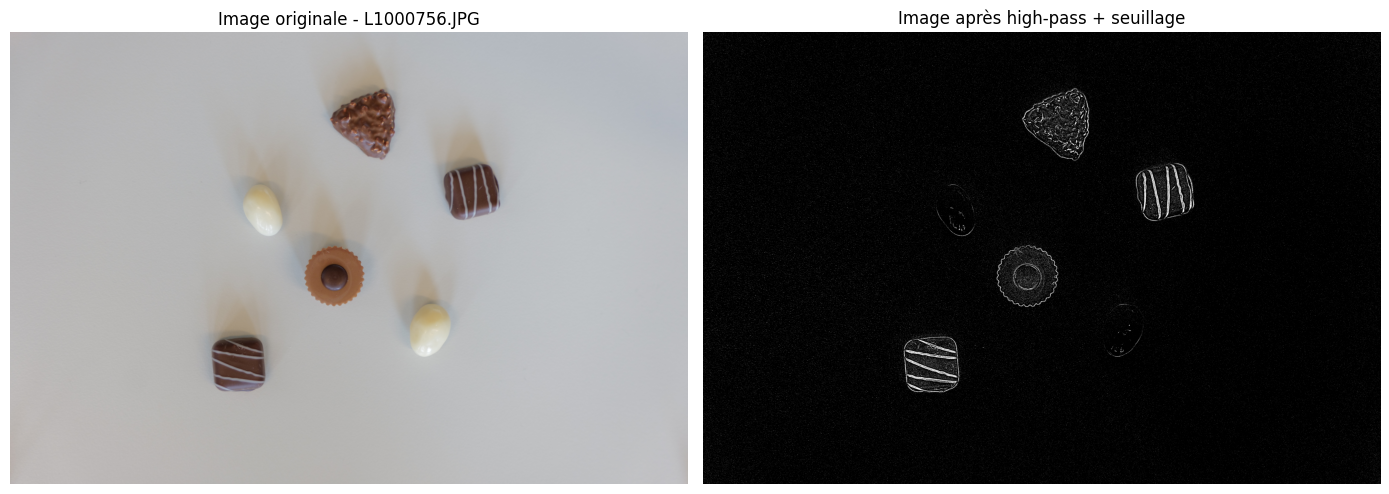

Traitement de : L1000763.JPG
std = 21.657113962960754, mean = 166.91761141666666
std des contours = 5.454003570128622


In [ ]:

# Dossier des images
img_dir = "dataset_project_iapr2025/train/"
img_files = sorted([f for f in os.listdir(img_dir) if f.lower().endswith(".jpg")])

# Itérer sur toutes les images
for filename in img_files:
    print(f"Traitement de : {filename}")
    path = os.path.join(img_dir, filename)

    # === Ton pipeline (inchangé) ===
    img = cv.imread(path)
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    imgGray = cv.cvtColor(img_rgb, cv.COLOR_BGR2GRAY)
    std = np.std(imgGray)
    mean = np.mean(imgGray)
    print(f"std = {std}, mean = {mean}")
    img_edges_std = np.std(cv.Canny(imgGray, 50, 200))
    print(f"std des contours = {img_edges_std}")

    low_pass = cv.GaussianBlur(imgGray, (45, 45), 3)
    high_pass = cv.subtract(imgGray, low_pass)
    _, thresholded = cv.threshold(high_pass, 2, 255, cv.THRESH_BINARY)


    fig, axs = plt.subplots(1, 2, figsize=(14, 14))
    axs[0].imshow(img_rgb)
    axs[0].set_title(f"Image originale - {filename}")
    axs[0].axis("off")

    axs[1].imshow(thresholded, cmap='gray')
    axs[1].set_title("Image après high-pass + seuillage")
    axs[1].axis("off")
    
    plt.tight_layout()
    plt.show()


In [9]:
from skimage.morphology import remove_small_objects, closing, square


def apply_closing(mask, size):
    return closing(mask > 0, square(size))


def remove_objects(binary_mask, min_size):
    return remove_small_objects(binary_mask > 0, min_size=min_size)


def detect_chocolates(img, size=45):
    # Prétraitement
    std = np.std(cv.cvtColor(255 - img, cv.COLOR_BGR2GRAY))
    img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Détection des pixels où R, G et B sont tous entre 170 et 190
    mask_rgb = (
        (img[:, :, 0] >= 160) &  (img[:, :, 0] <= 190) &# R
        (img[:, :, 1] >= 160) &  (img[:, :, 1] <= 190) &# G
        (img[:, :, 2] >= 160) &  (img[:, :, 2] <= 190)# B
    )

    # Appliquer la couleur blanche aux pixels correspondants
    img[mask_rgb] = [255, 255, 255]

    img_hsv = cv.cvtColor(img, cv.COLOR_RGB2HSV)

    mask_hsv = (
        (img_hsv[:, :, 1] >= 0) &  (img_hsv[:, :, 1] <= 20)
    )
    img[mask_hsv] = [255, 255, 255]


    img = cv.resize(img, (0, 0), fx=0.25, fy=0.25)
    img_copy = img.copy()


    img_edges_std = np.std(cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 50, 200))

    # Paramètres adaptatifs, mais appliqués sans disjonction finale
    remove_objects_size = 120
    thres2 = 3
    sigma = 2.7
    p2 = 38
    th_sigma = 2.7
    open_th = 6

    img[:, :, 0] = img[:, :, 0] * 0.25  # red
    img[:, :, 1] = img[:, :, 1] * 0.25  # green
    img[:, :, 2] = img[:, :, 2] * 1     # blue

    imgGray = cv.cvtColor(255 - img, cv.COLOR_BGR2GRAY)

    low_pass = cv.GaussianBlur(imgGray, (size, size), sigma)
    high_pass = cv.subtract(imgGray, low_pass)
    _, thresholded = cv.threshold(high_pass, thres2, 255, cv.THRESH_BINARY)

    thresholded = np.uint8(remove_objects(thresholded, remove_objects_size) * 255)
    thresholded_closing = apply_closing(thresholded, open_th)
    thresholded_blur = cv.GaussianBlur(thresholded_closing.astype(np.uint8) * 255, (size, size), th_sigma)

    contours, _ = cv.findContours(thresholded_blur, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
    chocolates = [cnt for cnt in contours if 2000 < cv.contourArea(cnt) < 50000]
    

    for cnt in chocolates:
        area = cv.contourArea(cnt)
        M = cv.moments(cnt)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            cx, cy = cnt[0][0]
        cv.putText(img_copy, f"{area}", (cx, cy), cv.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)


    
    for cnt in chocolates:
        cv.drawContours(img_copy, [cnt], -1, (255, 0, 0), 3)
        length = int(cv.arcLength(cnt, True))
        M = cv.moments(cnt)
        if M["m00"] != 0:
            cx = int(M["m10"] / M["m00"])
            cy = int(M["m01"] / M["m00"])
        else:
            cx, cy = cnt[0][0]
        cv.putText(img_copy, f"{length}px", (cx, cy), cv.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
    
    return img_copy, len(chocolates)

# Traitement de toutes les images dans un dossier
input_dir = "dataset_project_iapr2025/train"
image_files = [f for f in os.listdir(input_dir) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

from scipy.signal import find_peaks

for file in sorted(image_files):
    img_path = os.path.join(input_dir, file)
    img = cv.imread(img_path)
    result_img, count = detect_chocolates(img)

    # Détection des pixels où R, G et B sont tous entre 170 et 190
    mask_rgb = (
        (img[:, :, 0] >= 160) &  (img[:, :, 0] <= 190) &  # R
        (img[:, :, 1] >= 160) &  (img[:, :, 1] <= 190) &  # G
        (img[:, :, 2] >= 160) &  (img[:, :, 2] <= 190)    # B
    )
    img[mask_rgb] = [255, 255, 255]

    img_rgb = cv.cvtColor(cv.resize(img, (0, 0), fx=0.25, fy=0.25), cv.COLOR_BGR2RGB)
    img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

    mask_hsv = (
        (img_hsv[:, :, 1] >= 0) &  (img_hsv[:, :, 1] <= 20)
    )
    img_rgb[mask_hsv] = [255, 255, 255]
    img_hsv = cv.cvtColor(img_rgb, cv.COLOR_RGB2HSV)

    # Masque pour exclure le blanc pur
    mask = ~np.all(img_rgb == [255, 255, 255], axis=-1)
    mask = mask.astype(np.uint8) * 255

    # Histogrammes
    r_hist = cv.calcHist([img_rgb], [0], mask, [256], [0, 256]).flatten()
    g_hist = cv.calcHist([img_rgb], [1], mask, [256], [0, 256]).flatten()
    b_hist = cv.calcHist([img_rgb], [2], mask, [256], [0, 256]).flatten()
    h_hist = cv.calcHist([img_hsv], [0], mask, [180], [0, 180]).flatten()
    s_hist = cv.calcHist([img_hsv], [1], mask, [256], [0, 256]).flatten()
    v_hist = cv.calcHist([img_hsv], [2], mask, [256], [0, 256]).flatten()

    fig = plt.figure(figsize=(20, 10))

    # Image avec détection
    ax1 = fig.add_subplot(2, 3, 1)
    ax1.imshow(result_img)
    ax1.set_title(f"{file} – {count} chocolat(s)")
    ax1.axis('off')

    # Histogrammes HSV
    ax3 = fig.add_subplot(2, 3, 2)
    for hist, color, label in zip([h_hist, s_hist, v_hist], ['purple', 'orange', 'gray'], ['H', 'S', 'V']):
        ax3.plot(hist, color=color, label=label)
        peaks, _ = find_peaks(hist, height=np.max(hist) * 0.05)
        for peak in peaks:
            ax3.annotate(str(peak), xy=(peak, hist[peak]), xytext=(peak, hist[peak] + 500),
                         ha='center', color=color, fontsize=8,
                         arrowprops=dict(arrowstyle='->', color=color, lw=0.8))
    ax3.set_title("Histogrammes HSV superposés")
    ax3.legend()

    plt.tight_layout()
    plt.show()


KeyboardInterrupt: 

### Paths :

In [5]:
dataset_dir = "dataset_project_iapr2025"
images_train_dir = os.path.join(dataset_dir, "train")
images_test_dir = os.path.join(dataset_dir, "test")

train_csv_path = os.path.join(dataset_dir, "train.csv")

In [6]:
dataframe_train = pd.read_csv(train_csv_path)
dataframe_train["filename"] = dataframe_train["id"].apply(lambda x: f"L{x:07d}.JPG")
print(dataframe_train)

          id  Jelly White  Jelly Milk  Jelly Black  Amandina  Crème brulée  \
0    1000001            1           0            0         0             0   
1    1000002            0           1            0         0             0   
2    1000003            0           0            1         0             0   
3    1000004            0           0            0         1             0   
4    1000005            0           0            0         0             1   
..       ...          ...         ...          ...       ...           ...   
98   1010031            0           0            0         0             0   
99   1010032            0           0            0         0             0   
100  1010035            0           0            0         0             0   
101  1010041            0           0            0         2             0   
102  1010045            1           1            1         1             1   

     Triangolo  Tentation noir  Comtesse  Noblesse  Noir authen

In [7]:
def check_image_sizes(image_dir):
    sizes = set()  # set() only keeps unique values
    
    for filename in os.listdir(image_dir):
        if filename.endswith(".JPG"):
            img_path = os.path.join(image_dir, filename)
            image = Image.open(img_path)
            sizes.add(image.size)  # Adds the size (width, height) to the set
    
    if len(sizes) > 1:
        print("Images are of different sizes:")
        print(sizes)
    else:
        print("Every image has the same size :", sizes)

check_image_sizes(images_train_dir)
check_image_sizes(images_test_dir)

Every image has the same size : {(6000, 4000)}
Every image has the same size : {(6000, 4000)}


### Datasets : 2 differents because we have a csv for the training set and we don't for the testing set

In [8]:
class ChocolateTrainDataset(Dataset): # inherits from Dataset class in PyTorch
    def __init__(self, dataframe, images_dir, transform=None):
        self.dataframe = dataframe # dataframe = raw data
        self.images_dir = images_dir # directory where images are stored
        self.transform = transform # transformations to be applied to images
        self.labels = dataframe.iloc[:, 1:-1].values # all columns except the first and last one (id and filename)
        self.filenames = dataframe["filename"].values

    def __len__(self):
        return len(self.dataframe) # number of samples in the dataset

    def __getitem__(self, idx): # will be called each time we iterate over the dataset in a dataloader
        img_name = os.path.join(self.images_dir, self.filenames[idx])
        image = Image.open(img_name).convert("RGB")
        if self.transform:
            image = self.transform(image) # will be applied each time we iterate over the dataset in a dataloader
        
        label = torch.tensor(self.labels[idx], dtype=torch.float32)  # 13 classes
        return image, label
    
class ChocolateTestDataset(Dataset):
    def __init__(self, images_dir, transform=None):
        self.images_dir = images_dir
        self.transform = transform
        self.image_paths = sorted(glob.glob(os.path.join(images_dir, "*.JPG"))) # does not have a csv/dataframe like the training dataset => need to find the filenames by ourselves

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image


In [9]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Create the train dataset and dataloader WITHOUT normalization
train_dataset = ChocolateTrainDataset(dataframe_train, images_train_dir, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)


# Create the test dataset and dataloader WITHOUT normalization
test_dataset = ChocolateTestDataset(images_test_dir, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

In [10]:
def calculate_mean_std(dataloader):
    means = []
    stds = []
    for batch in dataloader: # enable to handle train_loader and test_loader
        if isinstance(batch, (list, tuple)): # batch is a tuple (images, labels) for train_loader
            images = batch[0]  # (images, labels)
        else: # batch is a tensor for test_loader
            images = batch  # (images,)
        means.append(torch.mean(images, dim=[0, 2, 3])) # size of the image is (batch_size, channels, height, width) => mean for each channel (RGB), output is (3,)
        stds.append(torch.std(images, dim=[0, 2, 3])) # std for each channel (RGB)
    
    mean = torch.mean(torch.stack(means), dim=0).numpy()
    std = torch.mean(torch.stack(stds), dim=0).numpy()
    return mean, std




# Calculate mean and std with the dataloader
mean_train, std_train = calculate_mean_std(train_loader)

print(f"Mean train: {mean_train}")
print(f"Std train: {std_train}")

# Data augmentation and normalization for training
transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=15, translate=(0.1, 0.1), scale=(0.9, 1.1)),  # Random translation and zoom
    transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 2.0)),  # Gaussian blur with random sigma
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_train, std=std_train) #normalization after data augmentation, with values calculated before augmentation but it is a good approximation
])

# Recreate the train dataset and dataloader WITH its normalization and data augmentation
train_dataset = ChocolateTrainDataset(dataframe_train, images_train_dir, transform=transform_train)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)



# Calculate mean and std with the dataloader
mean_test, std_test = calculate_mean_std(test_loader)

print(f"Mean test: {mean_test}")
print(f"Std test: {std_test}")

# We do NOT apply data augmentation on the test dataset, only normalization
transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean_test, std=std_test)
])

# Recreate the test dataset and dataloader WITH its normalization
test_dataset = ChocolateTestDataset(images_test_dir, transform=transform_test)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

Mean train: [0.6888842  0.66838366 0.6627756 ]
Std train: [0.1579174  0.15635023 0.17798379]
Mean test: [0.6871095  0.6585127  0.65092844]
Std test: [0.16302747 0.16433911 0.18869422]


### CNN : MAYBE WE NEED TO USE ATTENTION GATED POOLING LIKE LAB 3 ???????????????????????? 

In [11]:
class Attn_Net_Gated(nn.Module):
    def __init__(self, L: int, M: int):
        super().__init__()
        self.fc1_V = nn.Linear(L, M)
        self.fc1_U = nn.Linear(L, M)
        self.fc2 = nn.Linear(M, 1)

    def forward(self, x):
        att_tanh = torch.tanh(self.fc1_V(x))      # (N, M)
        att_sigmoid = torch.sigmoid(self.fc1_U(x))# (N, M)
        A = att_tanh * att_sigmoid                # (N, M)
        A = self.fc2(A)                           # (N, 1)
        return A


class AttentionPooling(nn.Module):
    def __init__(self, L: int, M: int):
        super().__init__()
        self.attention_net = Attn_Net_Gated(L, M)

    def forward(self, x, attention_only=False):
        coeffs = self.attention_net(x)     # (N, 1)
        A = F.softmax(coeffs, dim=0).T     # (1, N)
        Y = torch.matmul(A, x)             # (1, L)
        return A if attention_only else Y



class ChocolateCounterCNN(nn.Module):
    def __init__(self, patch_size=4, attn_dim=128):
        super().__init__()
        
        # CNN feature extractor
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),  # 3 -> 16
            nn.ReLU(),
            nn.MaxPool2d(2),  # 224 -> 112
            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 -> 32
            nn.ReLU(),
            nn.MaxPool2d(2),  # 112 -> 56
            nn.Conv2d(32, 64, kernel_size=3, padding=1), # 32 -> 64
            nn.ReLU(),
            nn.MaxPool2d(2),  # 56 -> 28
        )

        self.patch_size = patch_size
        self.embedding_dim = 64 * patch_size * patch_size
        self.attn_pool = AttentionPooling(L=self.embedding_dim, M=attn_dim)

        self.fc_layers = nn.Sequential(
            nn.Linear(self.embedding_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 13),    # 13 types de chocolats
            nn.ReLU()              # on veut des valeurs >= 0
        )

    def forward(self, x):
        features = self.conv_layers(x)  # (B, C, H, W)
        B, C, H, W = features.shape

        # Découpe en patchs via unfold
        patches = F.unfold(features, kernel_size=self.patch_size, stride=self.patch_size)  # (B, C*P*P, N)
        patches = patches.transpose(1, 2)  # (B, N, C*P*P)

        # Appliquer attention pooling à chaque image du batch
        pooled = torch.stack([self.attn_pool(patch) for patch in patches])  # (B, 1, C*P*P)
        pooled = pooled.squeeze(1)  # (B, C*P*P)

        output = self.fc_layers(pooled)  # (B, 13)
        return output
    
    @staticmethod # defines that the following function does not take self as input
    @torch.no_grad() # ensures that following function runs without tracking gradients
    # making the initialisation faster and more memory-efficient. The parameters remain trainable.
    def init_weights(module):
        if isinstance(module, nn.Conv2d):
            nn.init.kaiming_normal_(module.weight, mode='fan_out', nonlinearity='relu')
            if module.bias is not None:
                nn.init.constant_(module.bias, 0)
        elif isinstance(module, nn.BatchNorm2d):
            nn.init.constant_(module.weight, 1)
            nn.init.constant_(module.bias, 0)
        elif isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(module.weight, mode='fan_in', nonlinearity='relu')
            nn.init.constant_(module.bias, 0)
        """
        elif isinstance(module, nn.Linear):
            init.xavier_uniform_(m.weight)
            if m.bias is not None:
                init.constant_(m.bias, 0)
        
        """
        return
"""
class ChocolateCounterCNN(nn.Module):
    def __init__(self):
        super(ChocolateCounterCNN, self).__init__() # call the constructor of the parent class nn.Module
        
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), # 3 channels (RGB) -> 16 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 224x224 pixels to 112x112

            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 channels -> 32 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 112x112 pixels to 56x56

            nn.Conv2d(32, 64, kernel_size=3, padding=1), # 32 channels -> 64 channels
            nn.ReLU(),
            nn.MaxPool2d(2),  # from 56x56 pixels to 28x28

            nn.Conv2d(64, 128, kernel_size=3, padding=1), # 64 channels -> 128 channels
            nn.ReLU(),
            nn.MaxPool2d(2), # from 28x28 pixels to 14x14
        )

        self.fc_layers = nn.Sequential(
            nn.Flatten(), # flatten the output of the conv layers
            nn.Linear(128 * 14*14, 512), # 128 channels * (14*14) pixels to 512 neurons
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 13),  # 13 types of chocolates
            nn.ReLU() # don't want negative values for the output
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

"""
    
    

"\nclass ChocolateCounterCNN(nn.Module):\n    def __init__(self):\n        super(ChocolateCounterCNN, self).__init__() # call the constructor of the parent class nn.Module\n        \n        self.conv_layers = nn.Sequential(\n            nn.Conv2d(3, 16, kernel_size=3, padding=1), # 3 channels (RGB) -> 16 channels\n            nn.ReLU(),\n            nn.MaxPool2d(2),  # from 224x224 pixels to 112x112\n\n            nn.Conv2d(16, 32, kernel_size=3, padding=1), # 16 channels -> 32 channels\n            nn.ReLU(),\n            nn.MaxPool2d(2),  # from 112x112 pixels to 56x56\n\n            nn.Conv2d(32, 64, kernel_size=3, padding=1), # 32 channels -> 64 channels\n            nn.ReLU(),\n            nn.MaxPool2d(2),  # from 56x56 pixels to 28x28\n\n            nn.Conv2d(64, 128, kernel_size=3, padding=1), # 64 channels -> 128 channels\n            nn.ReLU(),\n            nn.MaxPool2d(2), # from 28x28 pixels to 14x14\n        )\n\n        self.fc_layers = nn.Sequential(\n            nn.Flat

In [12]:
actual_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = ChocolateCounterCNN().to(actual_device)  # <- modèle sur GPU
model.apply(ChocolateCounterCNN.init_weights) # applies initialisation, goes through every layers

summary(model, (3, 224, 224), device = actual_device.type)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 224, 224]             448
              ReLU-2         [-1, 16, 224, 224]               0
         MaxPool2d-3         [-1, 16, 112, 112]               0
            Conv2d-4         [-1, 32, 112, 112]           4,640
              ReLU-5         [-1, 32, 112, 112]               0
         MaxPool2d-6           [-1, 32, 56, 56]               0
            Conv2d-7           [-1, 64, 56, 56]          18,496
              ReLU-8           [-1, 64, 56, 56]               0
         MaxPool2d-9           [-1, 64, 28, 28]               0
           Linear-10                  [-1, 128]         131,200
           Linear-11                  [-1, 128]         131,200
           Linear-12                    [-1, 1]             129
   Attn_Net_Gated-13                    [-1, 1]               0
 AttentionPooling-14                 [-

## From practise 3 DL :

In [13]:
def mae(preds, target):
    return mean_absolute_error(target, preds)

def r2(preds, target):
    return r2_score(target, preds)


def train_epoch(model, optimizer, criterion, metrics, train_loader, device):
    
    # we activate the training state for the model
    model.train()

    # initialize epoch loss and metrics
    epoch_loss = 0
    epoch_metrics = dict(zip(metrics.keys(), torch.zeros(len(metrics))))

    # we iterate over the batches
    for batch_num, (x_batch, y_batch) in tqdm(enumerate(train_loader)):
        data = x_batch.to(device) # (batch_size, channels, height, width)
        target = y_batch.to(device) #Le terme device dans PyTorch fait référence à l'appareil (CPU ou GPU) sur lequel les tenseurs et les modèles sont stockés et exécutés.

        # Clean previously computed gradients
        optimizer.zero_grad()
        
        # Forward pass
        output = model(data) #calcule les prédictions du modèle. (scores bruts, pas encore les argmax)

        # Compute loss
        loss = criterion(output, target)

        # Compute gradients and optimize the model parameters
        loss.backward() #calcule les gradients
        optimizer.step() #met à jour les paramètres du modèle.
        
        '''
        Compute predictions and metrics
        Store predictions in variable preds
        No gradients should be propagated at this step
        '''
        with torch.no_grad(): #Cela garantit que PyTorch n'enregistre pas les opérations associées à torch.max() dans le graphe computationnel, ce qui évite une consommation mémoire excessive et optimise l'entraînement.
            preds = output.detach().cpu()
            target = target.detach().cpu()
            for k in epoch_metrics.keys():
                epoch_metrics[k] += metrics[k](preds, target)


        # log loss statistics
        epoch_loss += loss.item()

    # for the epoch loss, we take the average of the losses computed over the mini-batches
    epoch_loss /= len(train_loader)

    # for the epoch loss, we compute the average of the metrics over the mini-batches
    for k in epoch_metrics.keys():
          epoch_metrics[k] /= len(train_loader)

    clear_output() #clean the prints from previous epochs
    print('train Loss: {:.4f}, '.format(epoch_loss),
          ', '.join(['{}: {:.4f}'.format(k, epoch_metrics[k]) for k in epoch_metrics.keys()]))

    return epoch_loss,  epoch_metrics


In [14]:
def plot_training(train_loss, metrics_names, train_metrics_logs):
    fig, ax = plt.subplots(1, len(metrics_names) + 1, figsize=((len(metrics_names) + 1) * 5, 5))

    ax[0].plot(train_loss, c='blue', label='train')
    ax[0].set_title('Loss')
    ax[0].set_xlabel('epoch')
    ax[0].legend()

    for i in range(len(metrics_names)):
        ax[i + 1].plot(train_metrics_logs[i], c='blue', label='train')
        ax[i + 1].set_title(metrics_names[i])
        ax[i + 1].set_xlabel('epoch')
        ax[i + 1].legend()

    plt.show()

def update_metrics_log(metrics_names, metrics_log, new_metrics_dict):
    '''
    - metrics_names: the keys/names of the logged metrics
    - metrics_log: existing metrics log that will be updated
    - new_metrics_dict: epoch_metrics output from train_epoch and evaluate functions
    '''
    for i in range(len(metrics_names)):
        curr_metric_name = metrics_names[i]
        metrics_log[i].append(new_metrics_dict[curr_metric_name])
    return metrics_log

In [15]:
def train_cycle(model, optimizer, criterion, metrics, train_loader, n_epochs, device):
    train_loss_log = []
    metrics_names = list(metrics.keys())
    train_metrics_log = [[] for _ in range(len(metrics))]

    for epoch in range(n_epochs):
        print(f"Epoch {epoch+1} / {n_epochs}")
        train_loss, train_metrics = train_epoch(model, optimizer, criterion, metrics, train_loader, device)

        train_loss_log.append(train_loss)
        train_metrics_log = update_metrics_log(metrics_names, train_metrics_log, train_metrics)

        plot_training(train_loss_log, metrics_names, train_metrics_log)

    return train_metrics_log


train Loss: 0.5952,  MAE: 0.5895, R²: -0.0551


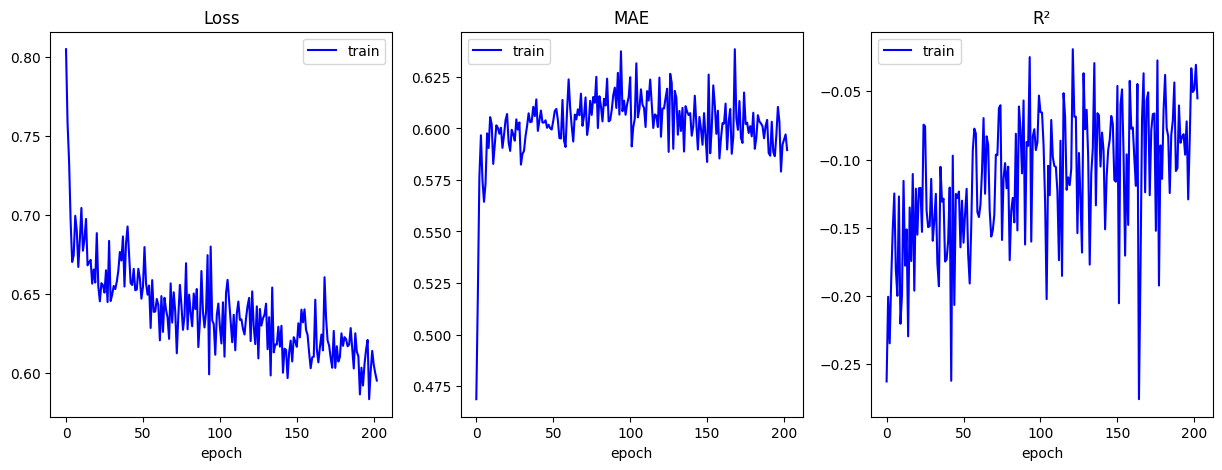

Epoch 204 / 500


0it [00:00, ?it/s]


KeyboardInterrupt: 

In [16]:
torch.manual_seed(42)

model = ChocolateCounterCNN()

metrics = {'MAE': mae, 'R²': r2}


#optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4) # or lr=1e-3

criterion = nn.MSELoss()  # or nn.L1Loss() if we want to be more robust to outliers or criterion = torch.nn.SmoothL1Loss()

N_EPOCHS = 500
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using {device}")

model.to(device)
criterion.to(device)

train_metrics_log = train_cycle(model, optimizer, criterion, metrics, train_loader=train_loader, n_epochs=N_EPOCHS, device=device)

# save model weights
results_models_weights_dir = 'models_weights/'
if not os.path.exists(results_models_weights_dir):
    os.mkdir(results_models_weights_dir)
torch.save(model.state_dict(), results_models_weights_dir + 'base_model.pth')

### Create predictions csv :

In [ ]:
# List of chocolate names (13 classes), the order is the same as in the dataframe
chocolate_names = [
    "Jelly White", "Jelly Milk", "Jelly Black",
    "Amandina", "Crème brulée", "Triangolo",
    "Tentation noir", "Comtesse", "Noblesse",
    "Noir authentique", "Passion au lait", "Arabia",
    "Stracciatella"
]

def generate_predictions_csv(model, test_loader, device, output_path="submission.csv"):
    model.eval()
    predictions = []
    image_ids = []

    with torch.no_grad():
        for batch_idx, x_batch in tqdm(enumerate(test_loader)):

            x_batch = x_batch.to(device)
            outputs = model(x_batch)
            outputs = torch.round(outputs).cpu().numpy().astype(int)

            # Find the image IDs from the filenames and store them in a list with the predictions
            batch_size = outputs.shape[0]
            for i in range(batch_size):
                # Example : extract "1000756" from ".../1000756.jpg"
                path = test_loader.dataset.image_paths[batch_idx * test_loader.batch_size + i]
                image_id_str = os.path.splitext(os.path.basename(path))[0]  # 'L1000757' for example
                image_id = int(re.sub(r'\D', '', image_id_str))  # Remove non-digit characters
                image_ids.append(image_id)
                predictions.append(outputs[i])

    # Creation of the DataFrame
    df = pd.DataFrame(predictions, columns=chocolate_names)
    df.insert(0, "id", image_ids)
    df.to_csv(output_path, index=False)
    print(f" CSV uploaded : {output_path}")


In [ ]:
# Assure-toi que le modèle est en mode évaluation et chargé sur le bon appareil
model.to(actual_device)

# Appelle la fonction
generate_predictions_csv(model, test_loader, actual_device)

0it [00:07, ?it/s]

batch_size 15
path dataset_project_iapr2025\test\L1000757.JPG


NameError: name 're' is not defined